In [6]:
import csv
import numpy as np
from scipy import optimize
from matplotlib import pyplot as plt

In [7]:
def costFun(params):
    cfsum = 0
    for idx in range(len(xindep)):
        cfsum += (params[0]*xindep[idx,0]+params[1]*xindep[idx, 1]+params[2]-ydep[idx])**2 # mom's height, dad's height, intercept
    return cfsum

In [8]:
with open('Birthweight_reduced_kg_R.csv') as f:
       linecount = sum(1 for line in f)
    
with open('Birthweight_reduced_kg_R.csv',newline='\n') as f:
    reader = csv.reader(f)
    babydata=np.zeros([linecount-1,3],'f')
    counter = 0
    for row in reader:
        if counter != 0:
            babydata[counter-1,0]=row[2]
            babydata[counter-1,1]=row[8]
            babydata[counter-1,2]=row[13]
        counter+=1

Linear model:  0.03559469765557291 *MHeight + -0.00642189156317848 *FHeight + ( -1.3816241852769704 )


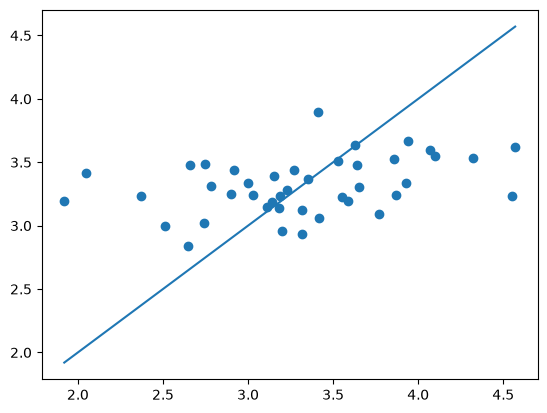

In [9]:
xindep=np.zeros([linecount-1],'f')
xindep=np.array(babydata[:,1:3]) # both parent's height
ydep=np.zeros([linecount-1],'f')
ydep=np.array(babydata[:,0])
firstGuess = [0.0, 0.0, 0.0]
result = optimize.minimize(costFun, firstGuess)
print("Linear model: ",result.x[0],"*MHeight +",result.x[1],"*FHeight + (", result.x[2],")")
# trying to do a graph, where X is the real birthweight, Y - predicted, diagonal line in that case shows ideal predictions, when real in predicted weights are matching
predictedBirthweight = result.x[0]*xindep[:,0] + result.x[1]*xindep[:,1] + result.x[2]
plt.scatter(ydep, predictedBirthweight)
plt.plot([min(ydep), max(ydep)], [min(ydep), max(ydep)])
plt.show()

### Exercise 3

The linear model was extended to two independent variables: mother's and father's height.

The optimizer now estimates three parameters instead of two.

Quadratic model: 0.0009068362447355493 *MHeight^2 + -0.2646481532798549 *MHeight + 22.2724175185346


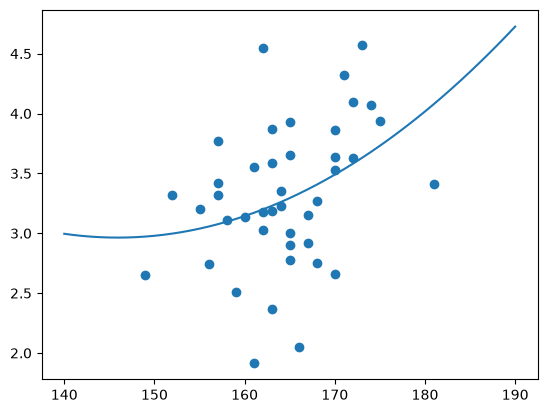

In [10]:

# Bonus task, Quadratic model for the dependence of baby weight and mothers height

mheight = babydata[:, 1]
birthweight = babydata[:, 0]
a, b, c = np.polyfit(mheight, birthweight, 2)
print("Quadratic model:", a, "*MHeight^2 +", b, "*MHeight +", c) # Print the quadratic model with its calculated coefficients: a,b,c 
x = [i for i in range(140, 191)]
y = [a*z**2 + b*z + c for z in x]
plt.plot(x,y)
plt.scatter(mheight, birthweight)
plt.show()


I also tried a quadratic model for the mother's height using np.polyfit(). The plot shows the model curve and the original data points.